Bag-of-Words and Skip-gram

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils.rnn import pad_sequence

# Example sentences
sentences = [
    ["I", "love", "chocolate"],
    ["I", "love", "ice", "cream"],
    ["I", "enjoy", "playing", "tennis"]
]

# Create vocabulary
vocab = set([word for sentence in sentences for word in sentence])
word2idx = {word: idx for idx, word in enumerate(vocab)}
idx2word = {idx: word for idx, word in enumerate(vocab)}
vocab_size = len(vocab)

# Generate training data
window_size = 4
train_data = []
for sentence in sentences:
    for i, target_word in enumerate(sentence):
        context_words = [sentence[j] for j in range(max(0, i - window_size), min(i + window_size + 1,len(sentence) )) if j>=0 and j != i]
        train_data.append((context_words, target_word))

print(train_data)

# Generate input and output pairs for CBOW
train_inputs, train_labels = [], []
for context_words, target_word in train_data:
    context_idxs = [word2idx[word] for word in context_words]
    train_inputs.append(torch.tensor(context_idxs, dtype=torch.long))
    train_labels.append(word2idx[target_word])

# Pad sequences to ensure uniform input length for batching
# Use pad_sequence for PyTorch, it pads to the longest sequence in the batch
# For CBOW, all context windows are usually fixed size, but if not, this handles it.
# Here we want to pad to `window_size * 2` based on the original Keras setup.
max_len_context = window_size * 2 # Based on the original Keras pad_sequences `maxlen`

def pad_to_maxlen(sequences, maxlen, padding_value=0):
    padded_sequences = []
    for seq in sequences:
        if len(seq) < maxlen:
            padded_seq = torch.cat([seq, torch.full((maxlen - len(seq),), padding_value, dtype=torch.long)])
        else:
            padded_seq = seq[:maxlen]
        padded_sequences.append(padded_seq)
    return torch.stack(padded_sequences)

train_inputs_padded = pad_to_maxlen(train_inputs, maxlen=max_len_context, padding_value=word2idx.get('<pad>', 0))
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)

# Define CBOW model using PyTorch
class CBOW(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super(CBOW, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.linear = nn.Linear(embedding_dim, vocab_size)

    def forward(self, inputs):
        # inputs shape: (batch_size, max_len_context)
        embedded = self.embedding(inputs)  # embedded shape: (batch_size, max_len_context, embedding_dim)
        # Sum the embeddings of the context words (average is also common)
        sum_embedded = embedded.sum(dim=1)  # sum_embedded shape: (batch_size, embedding_dim)
        output = self.linear(sum_embedded) # output shape: (batch_size, vocab_size)
        return output

embedding_dim = 10
cbow_model = CBOW(vocab_size, embedding_dim)

# Compile and train the CBOW model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cbow_model.parameters(), lr=0.001)

num_epochs = 10
for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = cbow_model(train_inputs_padded)
    loss = criterion(outputs, train_labels_tensor)
    loss.backward()
    optimizer.step()
    print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item():.4f}')

# Get the learned word embeddings
word_embeddings = cbow_model.embedding.weight.data.numpy()

# Print the word embeddings
for i, embedding in enumerate(word_embeddings):
    if i < vocab_size: # Ensure we don't try to access out of bounds if padding was introduced
        word = idx2word[i]
        print(f"Word: {word}, Embedding: {embedding}")






from sklearn.metrics.pairwise import cosine_similarity

# Get embeddings for 'love' and 'chocolate' from the trained PyTorch model
embedding_love_idx = word2idx['love']
embedding_chocolate_idx = word2idx['chocolate']

embedding_love = word_embeddings[embedding_love_idx]
embedding_chocolate = word_embeddings[embedding_chocolate_idx]

similarity = cosine_similarity([embedding_love], [embedding_chocolate])
print(f"Cosine similarity between 'love' and 'chocolate': {similarity}")

[(['love', 'chocolate'], 'I'), (['I', 'chocolate'], 'love'), (['I', 'love'], 'chocolate'), (['love', 'ice', 'cream'], 'I'), (['I', 'ice', 'cream'], 'love'), (['I', 'love', 'cream'], 'ice'), (['I', 'love', 'ice'], 'cream'), (['enjoy', 'playing', 'tennis'], 'I'), (['I', 'playing', 'tennis'], 'enjoy'), (['I', 'enjoy', 'tennis'], 'playing'), (['I', 'enjoy', 'playing'], 'tennis')]
Epoch 1/10, Loss: 4.8689
Epoch 2/10, Loss: 4.8159
Epoch 3/10, Loss: 4.7633
Epoch 4/10, Loss: 4.7113
Epoch 5/10, Loss: 4.6597
Epoch 6/10, Loss: 4.6087
Epoch 7/10, Loss: 4.5583
Epoch 8/10, Loss: 4.5086
Epoch 9/10, Loss: 4.4594
Epoch 10/10, Loss: 4.4109
Word: love, Embedding: [-0.01918559  0.3267541  -1.010108    0.39235336 -0.47794455  0.99692285
 -2.1139314  -0.0657255  -0.83374697 -0.26369232]
Word: I, Embedding: [-0.86675674  0.34407222 -1.6200254  -0.26871338 -0.4759257  -1.0591217
  0.9548215   0.55356324 -0.33160436  2.576023  ]
Word: tennis, Embedding: [ 1.2351319  -1.1013439   0.84291023  0.73343265  0.36655

Embedding Models: Global Vector (GloVe) for Word representations

In [ ]:
from collections import defaultdict
import numpy as np
corpus = [    "I love chocolate",    "I love ice cream",    "I enjoy playing tennis"]
# Initialize vocabulary and co-occurrence matrix
vocab = set()
co_occurrence = defaultdict(float)

window_size = 4
# Iterate through the corpus to build vocabulary and co-occurrence matrix
for sentence in corpus:
    words = sentence.split()
    for i in range(len(words)):
        word = words[i]
        vocab.add(word)
        for j in range(max(0, i - window_size), min(i + window_size + 1, len(words))):
            if i != j:
                co_occurrence[(word, words[j])] += 1.0 / abs(i - j)


embedding_dim = 10
word_embeddings = {
    word: np.random.randn(embedding_dim) for word in vocab
}


learning_rate = 0.1
num_epochs = 100

# Gradient descent to update word embeddings
for epoch in range(num_epochs):
    total_loss = 0
    for (word_i, word_j), observed_count in co_occurrence.items():
        # Calculate dot product of word embeddings
        dot_product = np.dot(word_embeddings[word_i], word_embeddings[word_j])

        # Calculate difference and update
        diff = dot_product - np.log(observed_count)
        total_loss += 0.5 * diff**2
        gradient = diff * word_embeddings[word_j]
        word_embeddings[word_i] -= learning_rate * gradient

    print(f"Epoch: {epoch+1}, Loss: {total_loss}")

word_embeddings

Epoch: 1, Loss: 66.15526739783564
Epoch: 2, Loss: 2.4491719254381565
Epoch: 3, Loss: 0.3438708231173538
Epoch: 4, Loss: 0.058156682119712276
Epoch: 5, Loss: 0.023053082839506644
Epoch: 6, Loss: 0.009057562370521258
Epoch: 7, Loss: 0.00654147960481381
Epoch: 8, Loss: 0.0040228327335859225
Epoch: 9, Loss: 0.0034466647700411366
Epoch: 10, Loss: 0.002571864540995428
Epoch: 11, Loss: 0.0021707016366679225
Epoch: 12, Loss: 0.0017221748506757444
Epoch: 13, Loss: 0.0014307078011983531
Epoch: 14, Loss: 0.0011623780081144658
Epoch: 15, Loss: 0.0009620507408322495
Epoch: 16, Loss: 0.000791061273362642
Epoch: 17, Loss: 0.0006559276142896391
Epoch: 18, Loss: 0.0005434078008419532
Epoch: 19, Loss: 0.00045218488061027736
Epoch: 20, Loss: 0.00037664377545184485
Epoch: 21, Loss: 0.0003145938058467524
Epoch: 22, Loss: 0.0002631453630150721
Epoch: 23, Loss: 0.00022055018420945603
Epoch: 24, Loss: 0.00018511577601006466
Epoch: 25, Loss: 0.0001556167960444361
Epoch: 26, Loss: 0.00013098779123040603
Epoch: 

{'love': array([ 0.62872867, -2.19016682,  0.38999095,  0.37223751,  1.41222228,
        -3.64999326, -0.44866758,  0.5165432 , -1.08609915,  0.01440312]),
 'I': array([-0.4046172 , -0.74359571,  0.52847451, -0.1956249 ,  0.3076512 ,
        -0.23490868,  1.21665476, -0.77497533,  1.08792848,  1.49532898]),
 'tennis': array([ 1.45202969, -0.21233993,  1.21085794, -0.14115685,  2.00384733,
        -1.23208687, -0.44043381,  1.6832632 ,  0.17240203, -0.39432544]),
 'cream': array([ 1.20719834,  1.16934909, -1.25806051, -1.18052423, -0.61318833,
        -1.07319889,  0.43410582,  1.36123402,  1.39682451, -0.2427997 ]),
 'chocolate': array([ 0.42380275, -0.17243555,  0.09711228,  0.11311857, -0.8533423 ,
        -0.35368958, -1.49986068, -1.13300872,  0.8225158 , -0.29940554]),
 'playing': array([-0.63782682,  1.19867609,  0.93128626, -0.60227182, -0.35222716,
        -0.56256105,  1.06796845,  0.13082674, -0.58348446, -0.84050576]),
 'enjoy': array([-0.50033399, -0.73361871, -0.30759762, 

Measure Embeddings cosine similarity scores for determining the similar context into Contextual Language Models

In [ ]:
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
# Load an open-source embedding model
model = SentenceTransformer('gpt2')  # You can replace with another model if needed

# Fix: Set the padding token for the tokenizer
# GPT-2 does not have a default padding token, so we assign its EOS token as the pad token.
if model.tokenizer.pad_token is None:
    model.tokenizer.pad_token = model.tokenizer.eos_token

def cosine_similarity(vector1, vector2):
    dot_product = np.dot(vector1, vector2)
    norm_vector1 = np.linalg.norm(vector1)
    norm_vector2 = np.linalg.norm(vector2)
    return dot_product / (norm_vector1 * norm_vector2)

def euclidean_distance(vector1, vector2):
    return np.linalg.norm(vector1 - vector2)

def get_embedding(word):
    """
    Gets the embedding for a given word using SentenceTransformer.
    """
    return model.encode(word)

# Define your words
# words = ["mouse", "pizza", "rome", "italian", "Italy", "italy"]
words = ["I", "love" ,"chocolate", "ice cream", "enjoy", "playing", "tennis"]
base_word = "Me"

# Construct DataFrame
df = pd.DataFrame(words, columns=["word_1"])
df["word_2"] = base_word

# Precompute embeddings for efficiency
embeddings = {word: get_embedding(word) for word in words + [base_word]}

# Compute similarity metrics
df["cosine_similarity"] = df.apply(lambda r: cosine_similarity(embeddings[r.word_1], embeddings[r.word_2]), axis=1)
df["euclidean_distance"] = df.apply(lambda r: euclidean_distance(embeddings[r.word_1], embeddings[r.word_2]), axis=1)

print(df)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

      word_1 word_2  cosine_similarity  euclidean_distance
0          I     Me           0.993560           14.362137
1       love     Me           0.996936            8.941288
2  chocolate     Me           0.981019           47.244274
3  ice cream     Me           0.978919           58.688202
4      enjoy     Me           0.978950           62.682121
5    playing     Me           0.985565           13.785552
6     tennis     Me           0.985184           59.552769


Example of Completing Contextual Langauge Processing

['Un', 'bel', 'iev', 'able', '!']


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

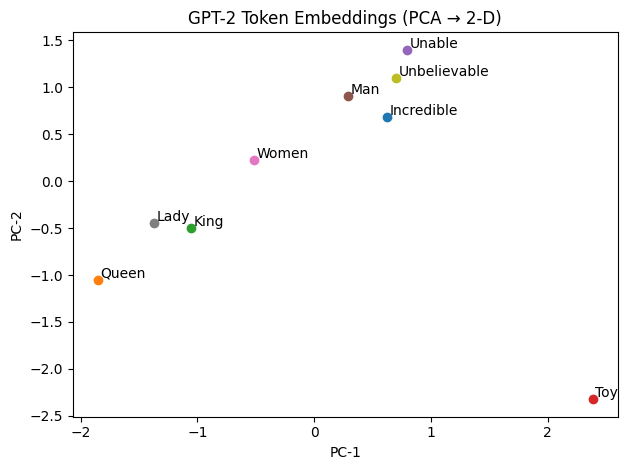

Incredible: [-0.079 -0.026  0.043 -0.106 -0.082]
Queen: [ 0.119 -0.138  0.236  0.006 -0.087]
 King: [ 0.102 -0.138  0.262 -0.051 -0.118]
  Toy: [ 0.333 -0.106  0.223 -0.105 -0.278]
Unable: [0.072 0.067 0.067 0.044 0.056]
  Man: [-0.028 -0.056  0.065 -0.017 -0.081]
Women: [-0.024  0.12   0.035 -0.014  0.01 ]
 Lady: [ 0.017 -0.1    0.164 -0.202  0.073]
Unbelievable: [0.032 0.024 0.097 0.028 0.036]


In [ ]:
# !pip install torch transformers scikit-learn matplotlib --quiet

# =========================
# 1. Setup
# =========================
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA   # swap for TSNE if you prefer
from transformers import AutoTokenizer

#----- text examples ----------
# Text to tokenize
text = "Unbelievable!"

# Initialize GPT-2 tokenizer
tok = AutoTokenizer.from_pretrained("gpt2")

# Tokenize the text and print the tokens
# This will split the text into subword tokens that GPT-2 can understand
print(tok.tokenize(text))    # Output: ['Un', 'bel', 'iev', 'able', '!']
#------------------------------

# =========================
# 2. Load Model and Tokenizer
# =========================
model_name = "gpt2"                     # Model to be used

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(
    model_name,
    torch_dtype=torch.float16,          # keeps RAM low without hurting the embeddings
    low_cpu_mem_usage=True,
    ).eval()                            # Puts the model in evaluation mode

# =========================
# 3. Tokenize & Create vector embedding
# =========================
WORDS = ["Incredible", "Queen", "King", "Toy", "Unable", "Man", "Women", "Lady", "Unbelievable"]        # Words to be tokenised

embed_vectors = []
for word in WORDS:
    ids          = tok(word, add_special_tokens=False)["input_ids"]
    ids_t        = torch.tensor(ids).unsqueeze(0)         # shape: (1, tokens)
    with torch.no_grad():
        token_vecs = model.get_input_embeddings()(ids_t)  # shape: (1, tokens, 768)
    # Pool sub-word pieces → single 768-D vector (mean works fine for single words)
    embed_vectors.append(token_vecs.mean(dim=1).squeeze().cpu().numpy())

vecs = np.stack(embed_vectors)             # List -> Matrix | shape: (len(WORDS), 768)

# =========================
# 4. PCA (Reduce to 2-D) & Visualisation
# =========================

coords = PCA(n_components=2, random_state=0).fit_transform(vecs)

plt.figure()
for (x, y), label in zip(coords, WORDS):
    plt.scatter(x, y)
    plt.text(x + 0.02, y + 0.02, label)
plt.title("GPT-2 Token Embeddings (PCA → 2-D)")
plt.xlabel("PC-1");  plt.ylabel("PC-2");  plt.tight_layout();  plt.show()

# Print the first few dimensions of the vectors
for w, v in zip(WORDS, vecs):
    print(f"{w:>5}: {np.round(v[:5], 3)}")

In [ ]:
import torch

# Define sequence length and embedding dimension
seq_len, d_model = 10, 8  # seq_len: number of positions, d_model: embedding dimension

# Create position indices tensor of shape (seq_len, 1)
pos = torch.arange(seq_len).unsqueeze(1)  # [[0], [1], [2], ..., [9]]

# Create dimension indices for even dimensions: [0, 2, 4, 6]
idx = torch.arange(0, d_model, 2)

# Calculate frequency/angle rates for each dimension
# As idx/d_model increases, 10000^(idx/d_model) increases exponentially
# This creates frequencies that vary from high (small idx) to low (large idx)
angle_rates = 1 / (10000 ** (idx / d_model))

# Initialize positional encoding matrix of shape (seq_len, d_model)
pe = torch.zeros(seq_len, d_model)

# Fill even indices with sine and odd indices with cosine
# pos * angle_rates creates a matrix of angles by broadcasting
pe[:, 0::2] = torch.sin(pos * angle_rates)  # sin for even dimensions (0,2,4,6)
pe[:, 1::2] = torch.cos(pos * angle_rates)  # cos for odd dimensions (1,3,5,7)

pe

tensor([[ 0.0000e+00,  1.0000e+00,  0.0000e+00,  1.0000e+00,  0.0000e+00,
          1.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 8.4147e-01,  5.4030e-01,  9.9833e-02,  9.9500e-01,  9.9998e-03,
          9.9995e-01,  1.0000e-03,  1.0000e+00],
        [ 9.0930e-01, -4.1615e-01,  1.9867e-01,  9.8007e-01,  1.9999e-02,
          9.9980e-01,  2.0000e-03,  1.0000e+00],
        [ 1.4112e-01, -9.8999e-01,  2.9552e-01,  9.5534e-01,  2.9995e-02,
          9.9955e-01,  3.0000e-03,  1.0000e+00],
        [-7.5680e-01, -6.5364e-01,  3.8942e-01,  9.2106e-01,  3.9989e-02,
          9.9920e-01,  4.0000e-03,  9.9999e-01],
        [-9.5892e-01,  2.8366e-01,  4.7943e-01,  8.7758e-01,  4.9979e-02,
          9.9875e-01,  5.0000e-03,  9.9999e-01],
        [-2.7942e-01,  9.6017e-01,  5.6464e-01,  8.2534e-01,  5.9964e-02,
          9.9820e-01,  6.0000e-03,  9.9998e-01],
        [ 6.5699e-01,  7.5390e-01,  6.4422e-01,  7.6484e-01,  6.9943e-02,
          9.9755e-01,  6.9999e-03,  9.9998e-01],
        [ 9.8936

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch.nn.functional as F

# Initialize model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("gpt2")
model = AutoModelForCausalLM.from_pretrained("gpt2")

# Print total number of tokens in GPT-2's vocabulary
print("GPT-2 vocab size:", tokenizer.vocab_size) # (should be 50257)

# Get vocabulary as list of (token, id) tuples and shuffle randomly
vocab_items = list(tokenizer.get_vocab().items())
np.random.shuffle(vocab_items)

# Print first 10 random token-ID pairs from vocabulary
# Token is displayed with repr() to show special characters/whitespace
print("\nSample of token→ID mappings:")
for token, idx in vocab_items[:10]:
    print(f"{idx:5d} → {repr(token)}")

# Input text to predict next token for
text = "Hello, how are you"

# Tokenize input
inputs = tokenizer(text, return_tensors="pt")

# Get model predictions
with torch.no_grad():  # No need to track gradients for inference
    outputs = model(**inputs)

# Get logits for last token
logits = outputs.logits[:, -1, :]  # Shape: [batch_size, vocab_size] -> torch.Size([1, 50257]) in this case

# Get raw logits for top 5 tokens before softmax
top_k = 5
top_logits, top_indices = torch.topk(logits[0], top_k)

# Convert logits to probabilities using softmax
probs = F.softmax(logits, dim=-1)

# Get top 5 probabilities after softmax
top_probs = probs[0][top_indices]

print(f"\nTop {top_k} predictions for next token after '{text}':")
print("-" * 50)
print("Raw Logits vs Softmax Probabilities")
print("-" * 50)
for logit, prob, idx in zip(top_logits, top_probs, top_indices):
    token = tokenizer.decode([idx])
    print(f"Token ID: {idx} | Token: {token:10} | Logit: {logit:.4f} | Probability: {prob:.4f}")



Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 vocab size: 50257

Sample of token→ID mappings:
17133 → 'EAR'
41715 → 'ĠMandal'
21944 → 'Vict'
 9562 → 'false'
25618 → 'Ġcouncill'
31566 → 'Ġ221'
31344 → 'Ġcustomization'
 6986 → 'Ġessentially'
 3727 → 'OD'
23902 → 'Ġbarred'

Top 5 predictions for next token after 'Hello, how are you':
--------------------------------------------------
Raw Logits vs Softmax Probabilities
--------------------------------------------------
Token ID: 1804 | Token:  doing     | Logit: -93.1168 | Probability: 0.2651
Token ID: 30 | Token: ?          | Logit: -93.6843 | Probability: 0.1503
Token ID: 4203 | Token:  feeling   | Logit: -93.7024 | Probability: 0.1476
Token ID: 1701 | Token: ?"         | Logit: -94.3397 | Probability: 0.0780
Token ID: 11 | Token: ,          | Logit: -95.1794 | Probability: 0.0337


----
# Homework

1. สร้างประโยคใหม่ "I am good at anwsering questions and I can take the test and pass the finance exam." จงนำ Contextual sentences แปลงเป็น Embeddings (ด้วยวิธีใดก็ได้) และให้คะแนนความคล้าย (Similarity score) ด้วยการวัดแบบ Euclidean และ Cosine similarity

คำอ้างอิง = "concern"?



2. นำประโยคเพียง "I am good at anwsering questions and I can take the test and pass the finance" ไปทำแปลงผ่าน Autotokenizer เป็น Embedding vectors ด้วยโมเดล GPT-2 และสร้างคำใหม่ผ่าน GPT-2 เช่นกัน ผลลัพธ์ที่ได้เป็นคำใดต่อไปใน 10 อันดับแรกของการทำนาย (Top-10) มีความน่าจะเป็นเท่าใด